#  Forward Computational Graphs & Dynamic Execution


In modern deep learning frameworks like PyTorch, automatic differentiation does not begin with gradients—it begins with **Directed Acyclic Graphs (DAGs)** dynamically recorded during the forward pass.

In this notebook, we explore the **define-by-run** paradigm: how standard Python functions, loops, and recursions automatically construct computational graphs through operator overloading, without requiring special compilation passes or decorators.

---

## Notebook Roadmap & Experiments

| # | Experiment | Pedagogical Focus | Key Insight |
|:---:|:---|:---|:---|
| **01** | **Python Function Interoperability** (`multiply_by_2`) | Polymorphism via operator overloading | Standard Python functions accept `Tensor` inputs seamlessly, automatically transforming numerical arithmetic into graph nodes. |
| **02** | **Dynamic Control Flow & Mutation** (`for` + `if/else`) | Branching & iterative graphs | Dynamic graphs capture Python control flow on the fly. Different execution branches record distinct DAG topologies. |
| **03** | **Recursive Graphs** (Fibonacci Tree) | Call-stack DAG construction | Function recursion constructs multi-branch DAGs directly mirroring the runtime execution tree. |
| **04** | **Computational Complexity Analysis** (DAG Growth) | Time & memory footprints | Analyzing how algorithmic choices (iterative $\mathcal{O}(n)$ vs. recursive $\mathcal{O}(\phi^n)$) physically scale the number of graph nodes and dependency edges. |
| **05** | **Visual Graph Debugging** (Trapping Rain Water) | Inspection vs. `print()` debugging | Inspecting intermediate node values and operation labels (`+`, `-`, `relu`) in a visual tree to identify subtle logical bugs that standard tracebacks miss. |

---

###  Visual Legend (The Tree Metaphor)
When rendering graphs with `draw_graph(root)`:
* **Green Nodes (Leaves)**: Independent inputs, constants, and parameters (`value` only, no parent operations).
* **Brown Nodes (Trunk & Branches)**: Intermediate operations (`op: add`, `op: mul`, `op: relu`) holding evaluated outputs.


In [28]:
import matplotlib.pyplot as plt
import numpy as np

from utorch.autograd import Tensor
from utorch.utils import count_nodes, draw_graph


In [2]:
def multiply_by_2(x):
    return x * 2

a = Tensor(10)

b = multiply_by_2(a)

b

Variable(value=20.0, fun=<lambda>)

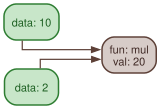

In [3]:
draw_graph(b)

In [4]:
count_nodes(b)

GraphStats(total=3, leaves=2, interim=1, edges=2, ops={func: 1})

In [5]:
a =  Tensor(2, name="a")
b = Tensor(3 )

for i in range(3):
  if i%2 == 0:
    b += a*b
  else:
    a += a*b
a

Variable(value=20.0, fun=<lambda>)

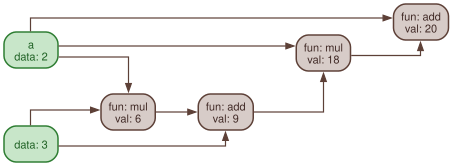

In [6]:
draw_graph(a)

In [7]:
count_nodes(a)

GraphStats(total=6, leaves=2, interim=4, edges=8, ops={func: 4})

In [8]:
def fib(n):
    if n <= 1:
        return n
    return fib(n - 1) + fib(n - 2)


In [9]:
n = fib(Tensor(10))

In [10]:
n

Variable(value=55.0, fun=<lambda>)

In [11]:
count_nodes(n)

GraphStats(total=441, leaves=177, interim=264, edges=528, ops={func: 264})

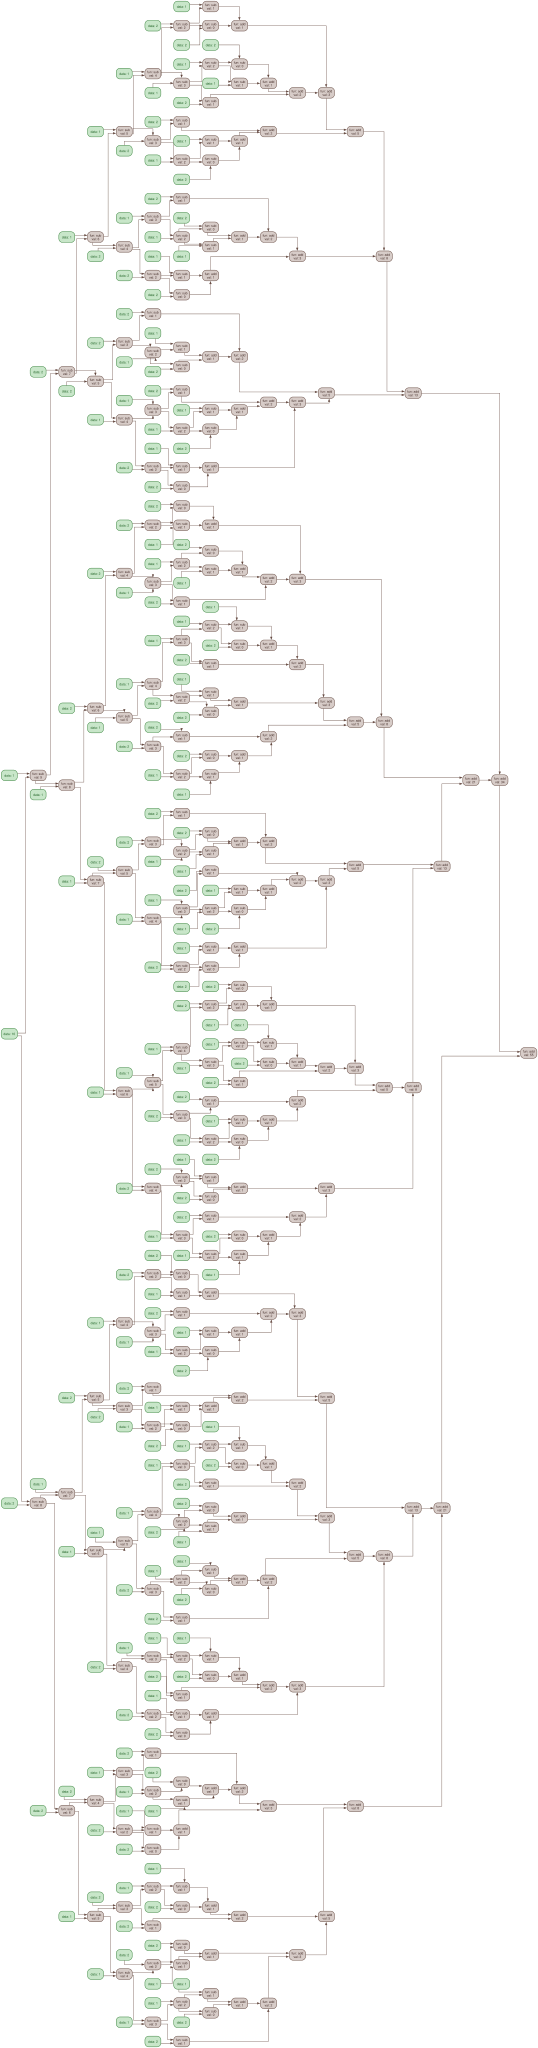

In [23]:
draw_graph(n, format='png')

In [23]:
def run_experiment(max_n: int = 25):
    n_values = list(range(2, max_n + 1))
    total_nodes = []

    for n in n_values:
        n = Tensor(n, name=f"n_{n}")
        result = fib(n)
        stats = count_nodes(result)

        total_nodes.append(stats.total)

    plt.figure(figsize=(9, 5))
    plt.plot(n_values, total_nodes, "o-", label="Total Nodes (n + 1)", color="#EE4C2C", lw=2)

    plt.title("utorch: Computational DAG Growth vs Fibonacci Input (n)", fontsize=13, fontweight="bold")
    plt.xlabel("Fibonacci Input (n)", fontsize=11)
    plt.ylabel("Count in Computational Graph", fontsize=11)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(frameon=True)
    plt.tight_layout()



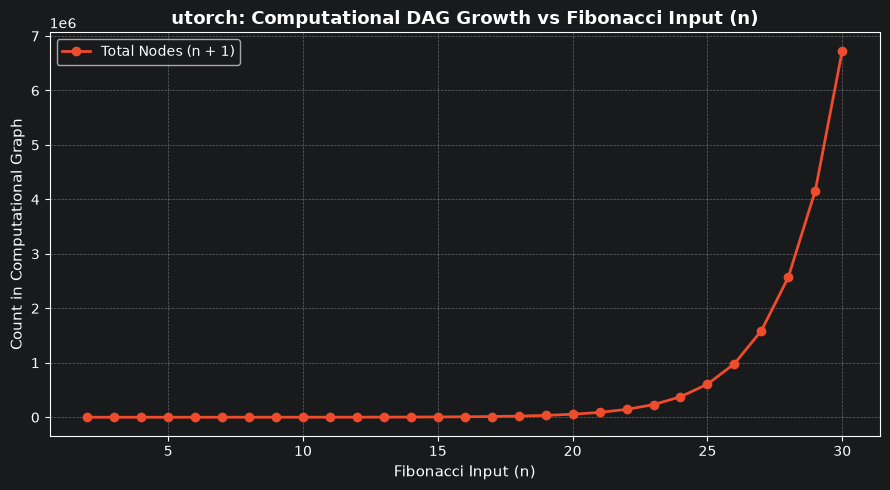

In [26]:
run_experiment(30);

###️ Experiment 05: Visual Graph Debugging — LeetCode #42: Trapping Rain Water

In complex vector operations, identifying where numerical logic breaks down via `print()` statements across large arrays is tedious and prone to human error.

By building a **computational graph**, we can visually inspect intermediate node values, operation labels, and edge flows in the tree structure to immediately pinpoint the root cause of subtle mathematical bugs.

---

###  Problem Statement

Given $n$ non-negative integers representing an elevation map where the width of each bar is $1$, compute how much water it can trap after raining.

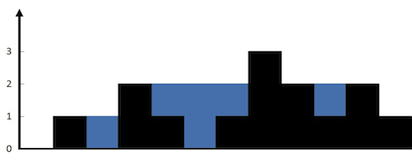


#### Mathematical Formulation
For each bar at index $i$, the water level is bounded by the **shorter** of the highest walls to its left and right:
$$\text{level}_i = \min\left(\max_{j \le i} h_j, \; \max_{k \ge i} h_k\right)$$

The trapped water above bar $i$ is then:
$$\text{water}_i = \max\Big(0, \; \text{level}_i - h_i\Big)$$

The total trapped water volume is the sum across all indices:
$$\text{Total Water} = \sum_{i=0}^{n-1} \text{water}_i$$

---

###  Test Cases & Specifications

#### Example 1
* **Input**: `height = [0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1]`
* **Expected Output**: `6`
* **Explanation**: The elevation map traps water in three separate reservoirs (between index 1–3, index 3–7, and index 7–10) totaling 6 units.

#### Example 2
* **Input**: `height = [4, 2, 0, 3, 2, 5]`
* **Expected Output**: `9`

#### Constraints
* $n == \text{len}(height)$
* $1 \le n \le 2 \times 10^4$
* $0 \le height[i] \le 10^5$



In [30]:
def trap_rain_water_fixed(height: Tensor) -> Tensor:
    """CORRECT implementation of Trapping Rain Water."""
    n = height.shape[0]
    raw_h = height.value

    left_max = np.maximum.accumulate(raw_h)
    right_max = np.maximum.accumulate(raw_h[::-1])[::-1]

    total_water = Tensor(0.0, name="total_water")

    for i in range(n):
        # FIX 1: Water is bounded by the SHORTER wall (min)
        bound = min(left_max[i], right_max[i])
        water_level = Tensor(bound, name=f"level_{i}")
        bar_h = Tensor(raw_h[i], name=f"h_{i}")

        # FIX 2: Apply .relu() so high bars cannot trap negative water
        water_i = (water_level - bar_h).relu()
        water_i.name = f"water_{i}"

        total_water = total_water + water_i

    return total_water


In [31]:
elevation = Tensor(np.array([0, 1, 0, 2, 1, 0, 1, 3, 2, 1, 2, 1]), name="elevation")

some_result = trap_rain_water_fixed(elevation)


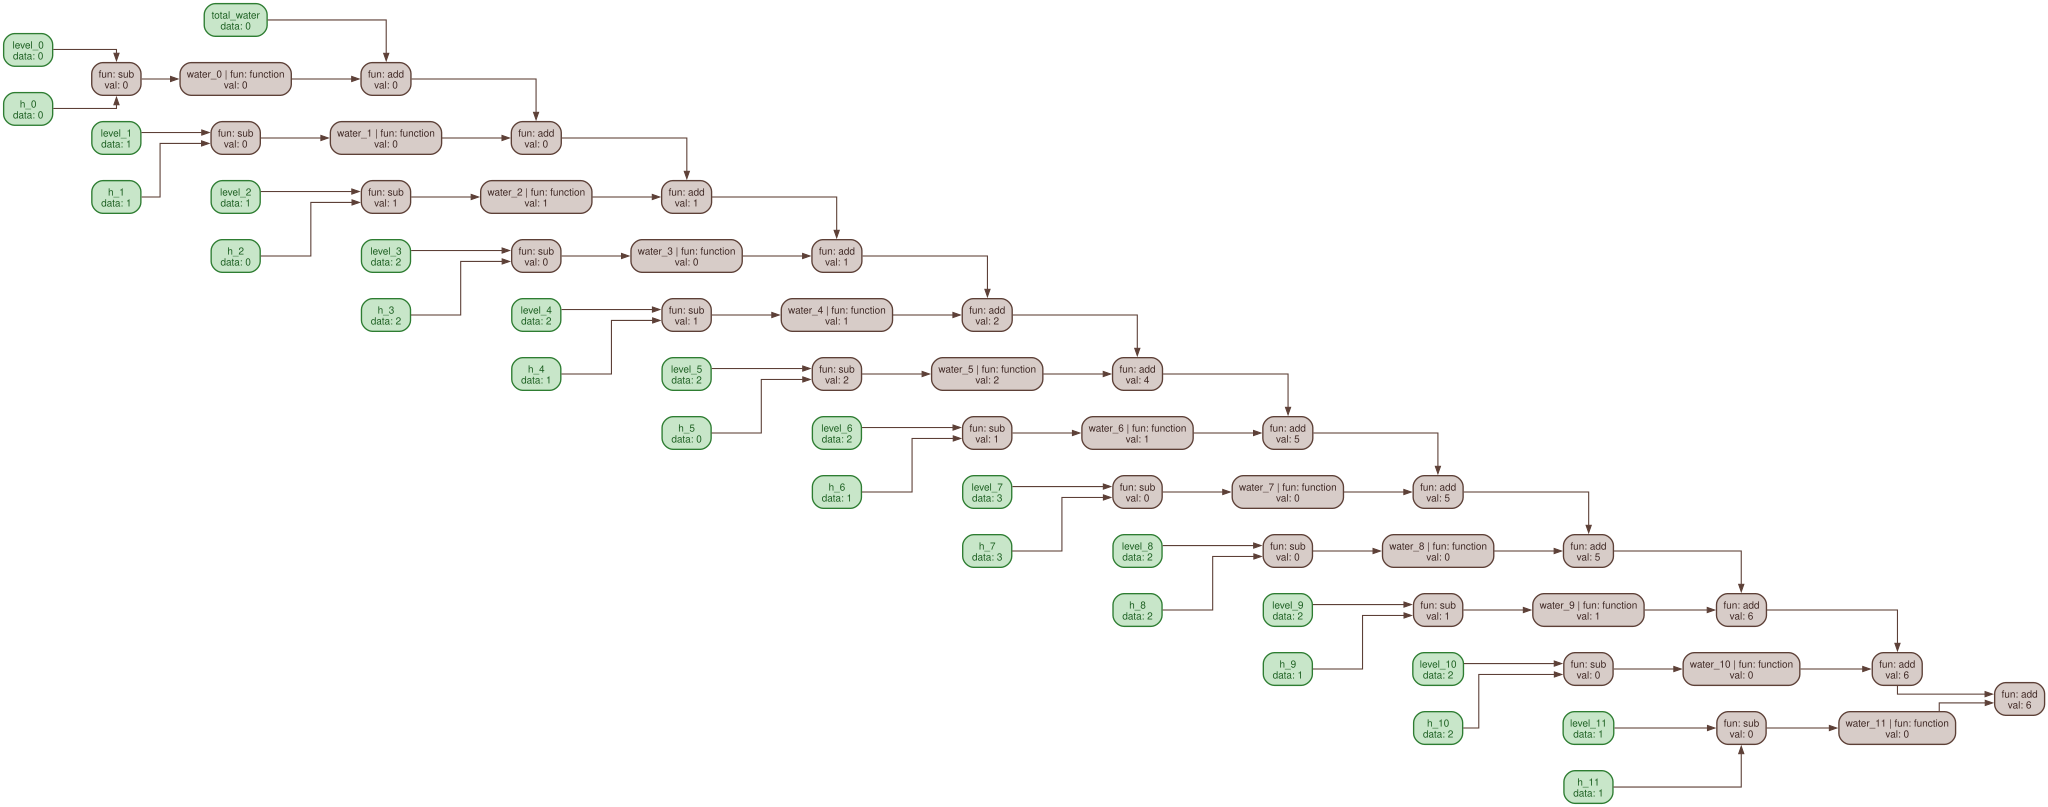

In [32]:
draw_graph(some_result)